In [20]:
import calendar
import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import requests
import seaborn as sns
import plotly.graph_objects as go

pd.set_option("display.max_columns", 50)
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

In [9]:
def inspect(df, name="data"):
    print(f"=== {name}: {df.shape[0]} rows x {df.shape[1]} columns ===")
    print(df.dtypes)
    print(df.isna().sum())
    display(df.head(3))

def prepare_trends(file_name, event_month=12, event_day=25, keep_terms=None, date_col="Time"):
    df = pd.read_csv(file_name).rename(columns={date_col: "date"})
    df["date"] = pd.to_datetime(df["date"])
    long = df.melt(id_vars="date", var_name="term", value_name="interest")
    long["interest"] = pd.to_numeric(long["interest"].replace("<1", 0))
    if keep_terms is not None:
        long = long[long["term"].isin(keep_terms)].copy()
    event_rows = df.loc[df["date"].dt.month == event_month, "date"]
    if event_rows.empty:
        raise ValueError(f"{file_name}: no dates in month {event_month} - is this the right file?")
    season = event_rows.dt.year.iloc[0]
    event = pd.Timestamp(year=season, month=event_month, day=event_day)
    long["season"] = season
    long["weeks_before_event"] = ((event - long["date"]).dt.days / 7).round()
    return long

def load_trends_folder(pattern, **kwargs):
    files = sorted(glob.glob(pattern))
    print(f"{pattern}: {len(files)} files found")
    return pd.concat([prepare_trends(f, **kwargs) for f in files], ignore_index=True)

def timing(group, factor=2, baseline_months=(9,), weeks_col="weeks_before_event", value_col="interest"):
    group = group.sort_values("date").reset_index(drop=True)
    baseline = group.loc[group["date"].dt.month.isin(baseline_months), value_col].mean()
    peak_pos = group[value_col].idxmax()
    above = group[value_col] >= factor * baseline
    start_pos = None
    for i in range(peak_pos + 1):
        if above.iloc[i:peak_pos + 1].all():
            start_pos = i
            break
    if start_pos is None:
        start_week, start_before = pd.NaT, float("nan")
    else:
        start_week, start_before = group.loc[start_pos, "date"], group.loc[start_pos, weeks_col]
    return pd.Series({"baseline": round(baseline, 1), "start_week": start_week,
                      "start_weeks_before": start_before,
                      "peak_week": group.loc[peak_pos, "date"],
                      "peak_weeks_before": group.loc[peak_pos, weeks_col]})

def timing_table(df, by=("season", "term"), **kwargs):
    per_group = df.groupby(list(by)).apply(lambda g: timing(g, **kwargs)).reset_index()
    averages = (per_group.groupby("term")[["start_weeks_before", "peak_weeks_before"]]
                .mean().round(1))
    return per_group, averages

In [10]:
files = sorted(glob.glob("set2_categories/*/*.csv"))
print(len(files))
files

36


['set2_categories\\alcohol\\alcohol_2020.csv',
 'set2_categories\\alcohol\\alcohol_2021.csv',
 'set2_categories\\alcohol\\alcohol_2022.csv',
 'set2_categories\\alcohol\\alcohol_2023.csv',
 'set2_categories\\alcohol\\alcohol_2024.csv',
 'set2_categories\\alcohol\\alcohol_2025.csv',
 'set2_categories\\books\\books_2020.csv',
 'set2_categories\\books\\books_2021.csv',
 'set2_categories\\books\\books_2022.csv',
 'set2_categories\\books\\books_2023.csv',
 'set2_categories\\books\\books_2024.csv',
 'set2_categories\\books\\books_2025.csv',
 'set2_categories\\clothing\\clothing_2020.csv',
 'set2_categories\\clothing\\clothing_2021.csv',
 'set2_categories\\clothing\\clothing_2022.csv',
 'set2_categories\\clothing\\clothing_2023.csv',
 'set2_categories\\clothing\\clothing_2024.csv',
 'set2_categories\\clothing\\clothing_2025.csv',
 'set2_categories\\electronics\\electronics_2020.csv',
 'set2_categories\\electronics\\electronics_2021.csv',
 'set2_categories\\electronics\\electronics_2022.csv',
 

In [11]:
terms = ["toys", "clothing", "electronics", "books", "alcohol", "groceries"]
cat_trends = pd.concat(
    [load_trends_folder(f"set2_categories/{t}/*.csv") for t in terms],
    ignore_index=True,
)
inspect(cat_trends, "category trends")

set2_categories/toys/*.csv: 6 files found
set2_categories/clothing/*.csv: 6 files found
set2_categories/electronics/*.csv: 6 files found
set2_categories/books/*.csv: 6 files found
set2_categories/alcohol/*.csv: 6 files found
set2_categories/groceries/*.csv: 6 files found
=== category trends: 657 rows x 5 columns ===
date                  datetime64[us]
term                             str
interest                       int64
season                         int32
weeks_before_event           float64
dtype: object
date                  0
term                  0
interest              0
season                0
weeks_before_event    0
dtype: int64


,date,term,interest,season,weeks_before_event
0,2020-08-30,toys,40,2020,17.0
1,2020-09-06,toys,43,2020,16.0
2,2020-09-13,toys,42,2020,15.0


In [12]:
display(cat_trends.groupby("term")["season"].unique())
cat_trends.groupby(["term", "season"]).size().unstack()

term
alcohol        [2020, 2021, 2022, 2023, 2024, 2025]
books          [2020, 2021, 2022, 2023, 2024, 2025]
clothing       [2020, 2021, 2022, 2023, 2024, 2025]
electronics    [2020, 2021, 2022, 2023, 2024, 2025]
groceries      [2020, 2021, 2022, 2023, 2024, 2025]
toys           [2020, 2021, 2022, 2023, 2024, 2025]
Name: season, dtype: object

season,2020,2021,2022,2023,2024,2025
term,,,,,,
alcohol,18,18,18,19,18,18
books,18,18,18,19,18,18
clothing,18,18,18,19,19,18
electronics,18,18,18,19,18,18
groceries,18,18,18,19,19,18
toys,18,18,18,19,19,18


In [13]:
sept = (cat_trends[cat_trends["date"].dt.month == 9]
        .groupby(["term", "season"])["interest"].mean()
        .rename("sept_avg"))
cat_trends = cat_trends.join(sept, on=["term", "season"])
cat_trends["vs_september"] = (cat_trends["interest"] / cat_trends["sept_avg"]).round(2)
cat_trends.head()

,date,term,interest,season,weeks_before_event,sept_avg,vs_september
0,2020-08-30,toys,40,2020,17.0,42.25,0.95
1,2020-09-06,toys,43,2020,16.0,42.25,1.02
2,2020-09-13,toys,42,2020,15.0,42.25,0.99
3,2020-09-20,toys,41,2020,14.0,42.25,0.97
4,2020-09-27,toys,43,2020,13.0,42.25,1.02


In [14]:
peak_rows = cat_trends.loc[cat_trends.groupby(["term", "season"])["interest"].idxmax()]
peak_table = (peak_rows.groupby("term")
              .agg(peak_vs_september=("vs_september", "mean"),
                   peak_weeks_before=("weeks_before_event", "mean"))
              .round(2)
              .sort_values("peak_vs_september", ascending=False))
peak_table

,peak_vs_september,peak_weeks_before
term,,
toys,2.12,2.33
electronics,1.29,6.33
clothing,1.27,4.83
alcohol,1.24,0.00
groceries,1.20,10.50
books,1.15,4.50


In [15]:
peak_dates = peak_rows.pivot(index="term", columns="season", values="date")
peak_dates.apply(lambda col: col.dt.strftime("%d %b"))

season,2020,2021,2022,2023,2024,2025
term,,,,,,
alcohol,27 Dec,26 Dec,25 Dec,24 Dec,29 Dec,21 Dec
books,13 Sep,05 Dec,11 Dec,10 Dec,08 Dec,07 Dec
clothing,22 Nov,21 Nov,20 Nov,19 Nov,24 Nov,23 Nov
electronics,22 Nov,21 Nov,20 Nov,22 Oct,20 Oct,23 Nov
groceries,18 Oct,29 Aug,25 Dec,03 Sep,29 Sep,02 Nov
toys,06 Dec,12 Dec,11 Dec,10 Dec,08 Dec,07 Dec


In [21]:
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
NAMES = {"toys": "Toys", "clothing": "Clothing", "electronics": "Electronics",
         "books": "Books", "alcohol": "Alcohol", "groceries": "Groceries (control)"}
ORDER = ["toys", "clothing", "electronics", "books", "alcohol", "groceries"]

def clean_layout(fig, title, subtitle, height):
    fig.update_layout(
        title=dict(text=f"<b>{title}</b><br><span style='font-size:13px;color:#52514e'>{subtitle}</span>",
                   x=0, xanchor="left"),
        template="simple_white", height=height, width=1000,
        font=dict(family="Arial", size=13, color="#0b0b0b"),
        margin=dict(t=95, l=60, r=30, b=60),
    )
    return fig

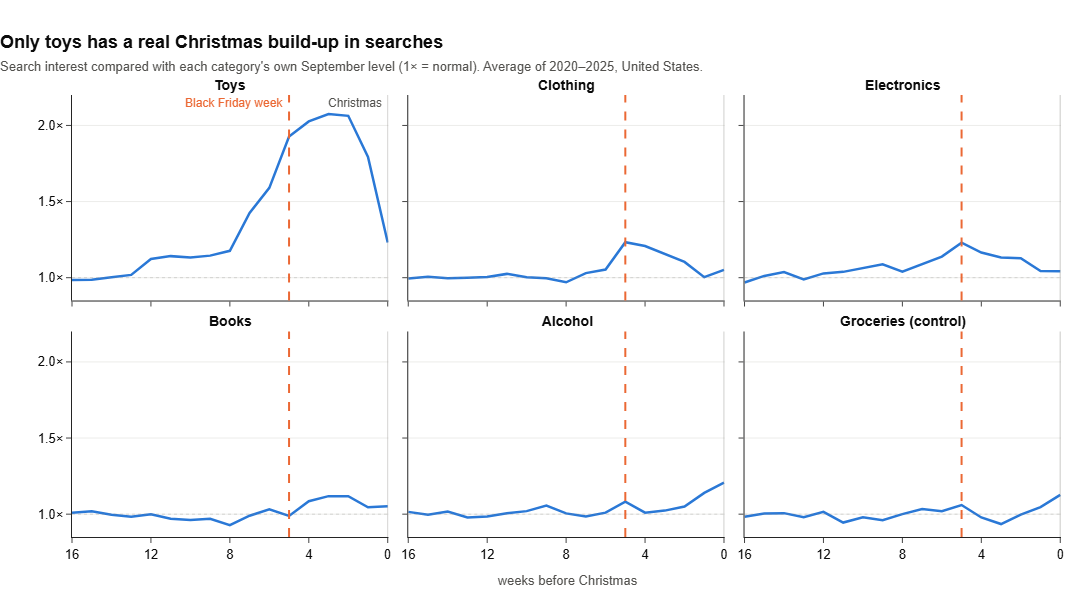

In [22]:
profile = (cat_trends.groupby(["term", "weeks_before_event"])["vs_september"]
           .mean().reset_index())
profile = profile[profile["weeks_before_event"].between(0, 16)].copy()
profile["x"] = -profile["weeks_before_event"]          # time runs left -> right
profile["category"] = profile["term"].map(NAMES)
profile["pct"] = ((profile["vs_september"] - 1) * 100).round(0)

fig1 = px.line(profile, x="x", y="vs_september", facet_col="category", facet_col_wrap=3,
               category_orders={"category": [NAMES[t] for t in ORDER]},
               custom_data=["weeks_before_event", "pct"])
fig1.update_traces(line=dict(color=BLUE, width=2.5),
                   hovertemplate="%{customdata[0]:.0f} weeks before Christmas<br>"
                                 "%{y:.2f}× September (%{customdata[1]:+.0f}%)<extra></extra>")
fig1.for_each_annotation(lambda a: a.update(text=f"<b>{a.text.split('=')[-1]}</b>", font_size=14))
fig1.add_hline(y=1, line=dict(color=GREY, width=1, dash="dot"))
fig1.add_vline(x=-5, line=dict(color=ORANGE, width=2, dash="dash"), opacity=1)   # Black Friday week
fig1.add_vline(x=0, line=dict(color=GREY, width=1.5))                            # Christmas
fig1.add_annotation(x=-5, y=2.15, xref="x4", yref="y4", text="Black Friday week", showarrow=False,
                    xanchor="right", xshift=-4, font=dict(color=ORANGE, size=12))
fig1.add_annotation(x=0, y=2.15, xref="x4", yref="y4", text="Christmas", showarrow=False,
                    xanchor="right", xshift=-4, font=dict(color="#52514e", size=12))
fig1.update_xaxes(tickvals=[-16, -12, -8, -4, 0], ticktext=["16", "12", "8", "4", "0"],
                  title_text="", showgrid=False)
fig1.add_annotation(text="weeks before Christmas", x=0.5, y=-0.12, xref="paper", yref="paper",
                    showarrow=False, font=dict(size=13, color="#52514e"))
fig1.update_yaxes(title_text="", tickformat=".1f", ticksuffix="×", range=[0.85, 2.2],
                  showgrid=True, gridcolor="#ececea")
fig1 = clean_layout(fig1, "Only toys has a real Christmas build-up in searches",
                    "Search interest compared with each category's own September level (1× = normal). "
                    "Average of 2020–2025, United States.", 600)
fig1.show()

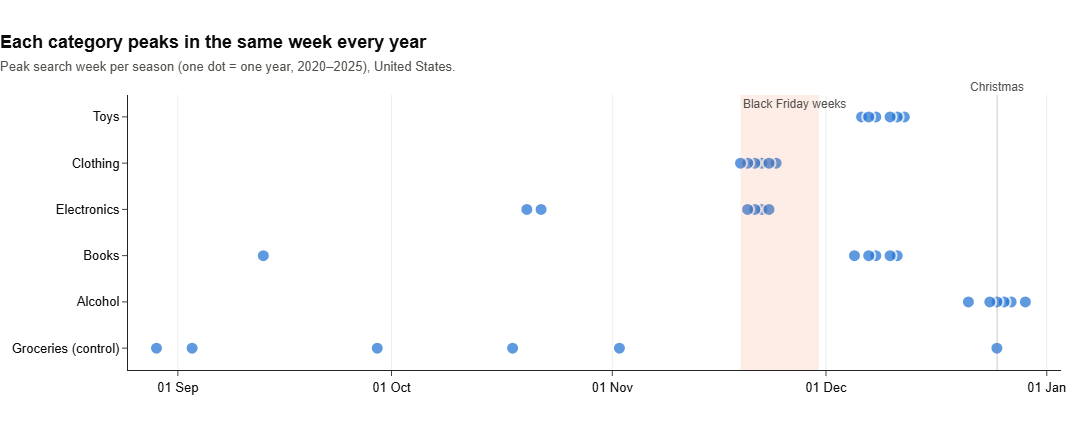

In [23]:
peaks = peak_rows.copy()
peaks["day"] = pd.to_datetime("2000-" + peaks["date"].dt.strftime("%m-%d"))  # put all years on one calendar
peaks["category"] = peaks["term"].map(NAMES)
peaks["label"] = peaks["date"].dt.strftime("%d %b %Y")

fig2 = go.Figure()
fig2.add_vrect(x0="2000-11-19", x1="2000-11-30", fillcolor=ORANGE, opacity=0.12, line_width=0,
               annotation_text="Black Friday weeks", annotation_position="top left",
               annotation_font=dict(color="#52514e", size=12))
fig2.add_vline(x=pd.Timestamp("2000-12-25").timestamp() * 1000, line=dict(color=GREY, width=1.5))
fig2.add_annotation(x="2000-12-25", y=1.06, yref="paper", text="Christmas", showarrow=False,
                    font=dict(color="#52514e", size=12))
fig2.add_trace(go.Scatter(
    x=peaks["day"], y=peaks["category"], mode="markers",
    marker=dict(size=13, color=BLUE, opacity=0.75, line=dict(color="white", width=2)),
    customdata=peaks[["label", "vs_september"]],
    hovertemplate="%{y}<br>peak week: %{customdata[0]}<br>%{customdata[1]:.2f}× September<extra></extra>",
))
fig2.update_xaxes(range=["2000-08-25", "2001-01-03"], tickformat="%d %b", dtick="M1",
                  showgrid=True, gridcolor="#ececea")
fig2.update_yaxes(categoryorder="array", categoryarray=[NAMES[t] for t in ORDER][::-1])
fig2 = clean_layout(fig2, "Each category peaks in the same week every year",
                    "Peak search week per season (one dot = one year, 2020–2025), United States.", 430)
fig2.show()

In [17]:
toys = cat_trends[cat_trends["term"] == "toys"]
per_season_toys, avg_toys = timing_table(toys, factor=1.5)
display(per_season_toys)
display(avg_toys)
for f in [1.3, 1.5, 2]:
    _, avg = timing_table(toys, factor=f)
    print(f"factor = {f}:", avg.to_dict("records"))

,season,term,baseline,start_week,start_weeks_before,peak_week,peak_weeks_before
0,2020,toys,42.2,2020-11-08,7.0,2020-12-06,3.0
1,2021,toys,52.2,2021-11-14,6.0,2021-12-12,2.0
2,2022,toys,47.2,2022-11-13,6.0,2022-12-11,2.0
3,2023,toys,45.5,2023-11-05,7.0,2023-12-10,2.0
4,2024,toys,49.0,2024-11-17,5.0,2024-12-08,2.0
5,2025,toys,48.0,2025-11-16,6.0,2025-12-07,3.0


,start_weeks_before,peak_weeks_before
term,,
toys,6.2,2.3


factor = 1.3: [{'start_weeks_before': 6.8, 'peak_weeks_before': 2.3}]
factor = 1.5: [{'start_weeks_before': 6.2, 'peak_weeks_before': 2.3}]
factor = 2: [{'start_weeks_before': 3.8, 'peak_weeks_before': 2.3}]


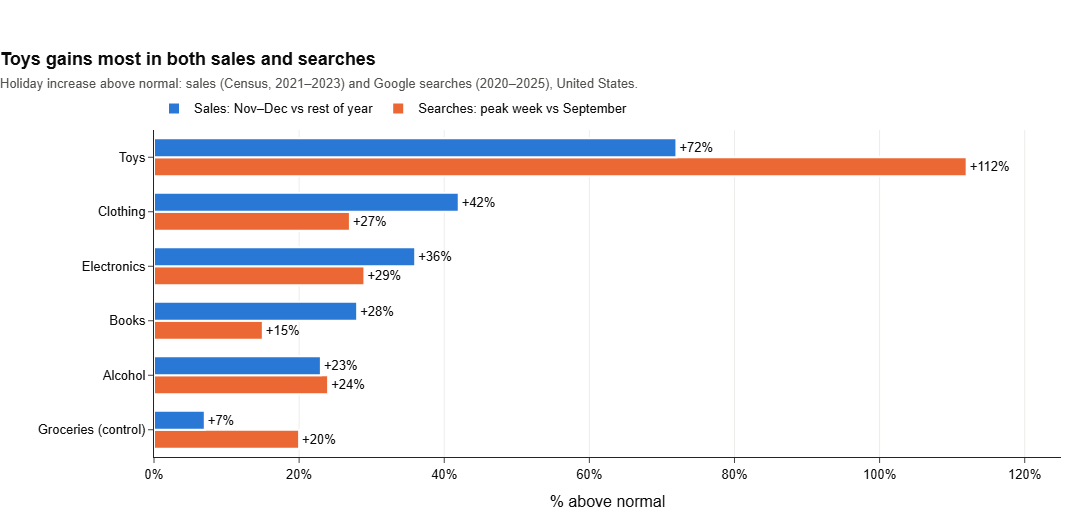

In [24]:
sales_lift = pd.DataFrame({"term": ORDER, "sales_lift": [1.72, 1.42, 1.36, 1.28, 1.23, 1.07]})
summary = peak_table.reset_index().merge(sales_lift, on="term")
summary["category"] = summary["term"].map(NAMES)
summary["Sales: Nov–Dec vs rest of year"] = ((summary["sales_lift"] - 1) * 100).round(0)
summary["Searches: peak week vs September"] = ((summary["peak_vs_september"] - 1) * 100).round(0)
long = summary.melt(id_vars="category",
                    value_vars=["Sales: Nov–Dec vs rest of year", "Searches: peak week vs September"],
                    var_name="measure", value_name="pct_above_normal")

fig3 = px.bar(long, x="pct_above_normal", y="category", color="measure", barmode="group",
              orientation="h", text="pct_above_normal",
              category_orders={"category": [NAMES[t] for t in ORDER],
                               "measure": ["Searches: peak week vs September", "Sales: Nov–Dec vs rest of year"]},
              color_discrete_map={"Sales: Nov–Dec vs rest of year": BLUE,
                                  "Searches: peak week vs September": ORANGE})
fig3.update_traces(texttemplate="+%{x:.0f}%", textposition="outside", cliponaxis=False,
                   marker_line_color="white", marker_line_width=2,
                   hovertemplate="%{y}<br>%{fullData.name}: +%{x:.0f}%<extra></extra>")
fig3.update_xaxes(title_text="% above normal", ticksuffix="%", range=[0, 125],
                  showgrid=True, gridcolor="#ececea")
fig3.update_yaxes(title_text="")
fig3.update_layout(legend=dict(title="", orientation="h", y=1.02, x=0, yanchor="bottom",
                               traceorder="reversed"), bargap=0.3)
fig3 = clean_layout(fig3, "Toys gains most in both sales and searches",
                    "Holiday increase above normal: sales (Census, 2021–2023) and Google searches (2020–2025), United States.", 520)
fig3.update_layout(margin=dict(t=130))
fig3.show()

In [19]:
peak_table.to_csv("results_set2_peak_table.csv")
summary.to_csv("results_set2_sales_vs_search.csv", index=False)
per_season_toys.to_csv("results_set2_toys_timing.csv", index=False)
print("saved 3 files")

saved 3 files
